In [3]:
import torch
import torchvision
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import math

# Pre-Configuration

In [4]:
SEED = 42
EPOCHS = 150
LEARNING_RATE = 0.0001

torch.manual_seed(SEED)
np.random.seed(SEED)

# Dataset

In [5]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 128

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
val_dataset = torchvision.datasets.CIFAR10(root="./data",train=True,download=True,transform=transform)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(trainset), generator=generator).tolist()
train_indices = indices[:45000]
val_indices = indices[45000:]
train_subset = Subset(trainset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = torch.utils.data.DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
valloader = DataLoader(val_subset,batch_size=batch_size,shuffle=False,num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [6]:
print("Training images:", len(trainset))
print("Testing images:", len(testset))

Training images: 50000
Testing images: 10000


[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.40784317 ... 0.854902   0.5        0.5       ]
  ...
  [0.5        0.5        0.12549019 ... 0.12941176 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.25882354 ... 0.86274517 0.5        0.5       ]
  ...
  [0.5        0.5        0.40000004 ... 0.35686275 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

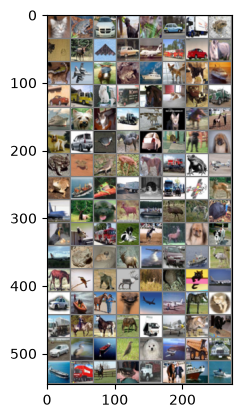

cat   frog  car   dog   frog  car   truck frog  cat   deer  plane car   plane truck car   horse cat   plane horse frog  ship  dog   dog   ship  car   truck dog   truck horse dog   car   truck ship  dog   cat   truck deer  cat   horse horse dog   car   bird  horse car   cat   dog   dog   frog  frog  bird  deer  horse truck frog  plane frog  ship  frog  truck dog   truck plane deer  plane deer  dog   deer  ship  bird  deer  bird  bird  bird  truck dog   horse deer  dog   dog   plane frog  dog   deer  plane car   ship  bird  horse bird  cat   deer  deer  bird  cat   plane car   ship  horse bird  plane plane horse cat   truck horse horse horse truck plane cat   cat   car   bird  ship  bird  dog   plane truck car   ship  truck horse cat   truck horse ship  ship 


In [7]:
def imshow(img):
    img = img / 2 + 0.5
    # normalize: 
    npimg = img.numpy()
    print(npimg)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()
dataiter = iter(train_loader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

# Softmax Model

In [8]:
class SoftmaxClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Input: 3 x 32 x 32 = 3072 values
        # Output: 10 logits
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(3 * 32 * 32, num_classes)

    def forward(self, x):
        x = self.flatten(x)  # [B, 3, 32, 32] -> [B, 3072]
        logits = self.fc(x)  # [B, 3072] -> [B, 10]
        return logits

# Define a Loss function and optimizer

In [9]:
import torch.optim as optim

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SoftmaxClassifier(num_classes=10).to(device)

# Explicitly initialize parameters
nn.init.xavier_uniform_(model.fc.weight)
nn.init.zeros_(model.fc.bias)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-3
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

# Training & Analysis

## Training

In [10]:
# Count model parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\n========== Model Information ==========")
print(model)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print("\nWeight shape:", tuple(model.fc.weight.shape))
print("Bias shape:", tuple(model.fc.bias.shape))

# Evaluation function
def evaluate(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            current_batch_size = labels.size(0)

            total_loss += loss.item() * current_batch_size
            predictions = logits.argmax(dim=1)

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += current_batch_size

    avg_loss = total_loss / total_samples
    accuracy = 100.0 * total_correct / total_samples

    return avg_loss, accuracy

# Training loop
history = {
    "epoch": [],
    "train_loss": [],
    "test_loss": [],
    "train_acc": [],
    "test_acc": [],
    "learning_rate": [],
    "precision": [],
    "recall": [],
    "f1_score": []
}

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Reset gradient
        optimizer.zero_grad()

        # Forward pass
        logits = model(images)

        # Compute loss
        loss = criterion(logits, labels)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Statistics
        current_batch_size = labels.size(0)

        running_loss += loss.item() * current_batch_size

        predictions = logits.argmax(dim=1)

        total_correct += (
            predictions == labels
        ).sum().item()

        total_samples += current_batch_size

    train_loss = running_loss / total_samples
    train_acc = 100.0 * total_correct / total_samples

    # Evaluate on test data after each epoch
    test_loss, test_acc = evaluate(
        model, valloader, criterion
    )

    # Record metrics
    scheduler.step(test_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.5f}"
    )



========== Model Information ==========
SoftmaxClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=3072, out_features=10, bias=True)
)
Total parameters: 30730
Trainable parameters: 30730

Weight shape: (10, 3072)
Bias shape: (10,)
Epoch [01/150] Train Loss: 1.9625 | Test Loss: 1.8666 | Train Acc: 30.68% | Test Acc: 35.22% | LR: 0.00010
Epoch [02/150] Train Loss: 1.8220 | Test Loss: 1.8256 | Train Acc: 37.42% | Test Acc: 37.24% | LR: 0.00010
Epoch [03/150] Train Loss: 1.7860 | Test Loss: 1.7957 | Train Acc: 38.93% | Test Acc: 38.94% | LR: 0.00010
Epoch [04/150] Train Loss: 1.7645 | Test Loss: 1.7792 | Train Acc: 39.74% | Test Acc: 39.86% | LR: 0.00010
Epoch [05/150] Train Loss: 1.7487 | Test Loss: 1.7673 | Train Acc: 40.41% | Test Acc: 39.60% | LR: 0.00010
Epoch [06/150] Train Loss: 1.7364 | Test Loss: 1.7626 | Train Acc: 40.92% | Test Acc: 39.96% | LR: 0.00010
Epoch [07/150] Train Loss: 1.7267 | Test Loss: 1.7497 | Train Acc: 41.31% | Test Acc: 40.30% 

## Save Model

In [11]:
PATH = './softmax_cifar10.pth'
torch.save(model.state_dict(), PATH)

# Testing

[[[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.61960787 ... 0.08235294 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.43921572 ... 0.09803921 0.5        0.5       ]
  ...
  [0.5        0.5        0.45882356 ... 0.00392157 0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5        0.5        ... 0.5        0.5        0.5       ]]

 [[0.5        0.5        0.5        ... 0.5        0.5        0.5       ]
  [0.5        0.5     

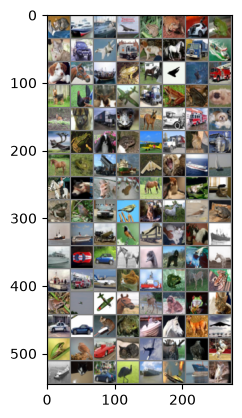

GroundTruth:  cat   ship  ship  plane frog  frog  car   frog  cat   car   plane truck dog   horse truck ship  dog   horse ship  frog  horse plane deer  truck dog   bird  deer  plane truck frog  frog  dog   deer  dog   truck bird  deer  car   truck dog   deer  frog  dog   frog  plane truck cat   truck horse frog  truck ship  plane cat   ship  ship  horse horse deer  frog  horse cat   frog  cat   frog  bird  car   bird  cat   horse bird  frog  ship  ship  plane bird  truck cat   cat   ship  ship  car   car   horse bird  dog   bird  horse ship  truck plane cat   ship  frog  deer  frog  frog  plane plane horse deer  dog   frog  cat   car   car   cat   frog  ship  horse deer  plane frog  bird  car   cat   plane deer  bird  horse ship  cat   car   bird  ship  plane ship  cat  


In [13]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [14]:
softm = SoftmaxClassifier(num_classes=10)
softm.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [15]:
outputs = softm(images)

In [16]:
_, predicted = torch.max(outputs, 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  cat   truck ship  plane


In [18]:
correct = 0
total = 0

with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = softm(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the Softmax Model on the 10000 test images: {100 * correct // total} %')

Accuracy of the Softmax Model on the 10000 test images: 41 %


In [23]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = softm(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 49.3 %
Accuracy for class: car   is 48.3 %
Accuracy for class: bird  is 27.9 %
Accuracy for class: cat   is 25.9 %
Accuracy for class: deer  is 30.6 %
Accuracy for class: dog   is 34.0 %
Accuracy for class: frog  is 50.3 %
Accuracy for class: horse is 45.5 %
Accuracy for class: ship  is 54.1 %
Accuracy for class: truck is 48.2 %


# Analysis

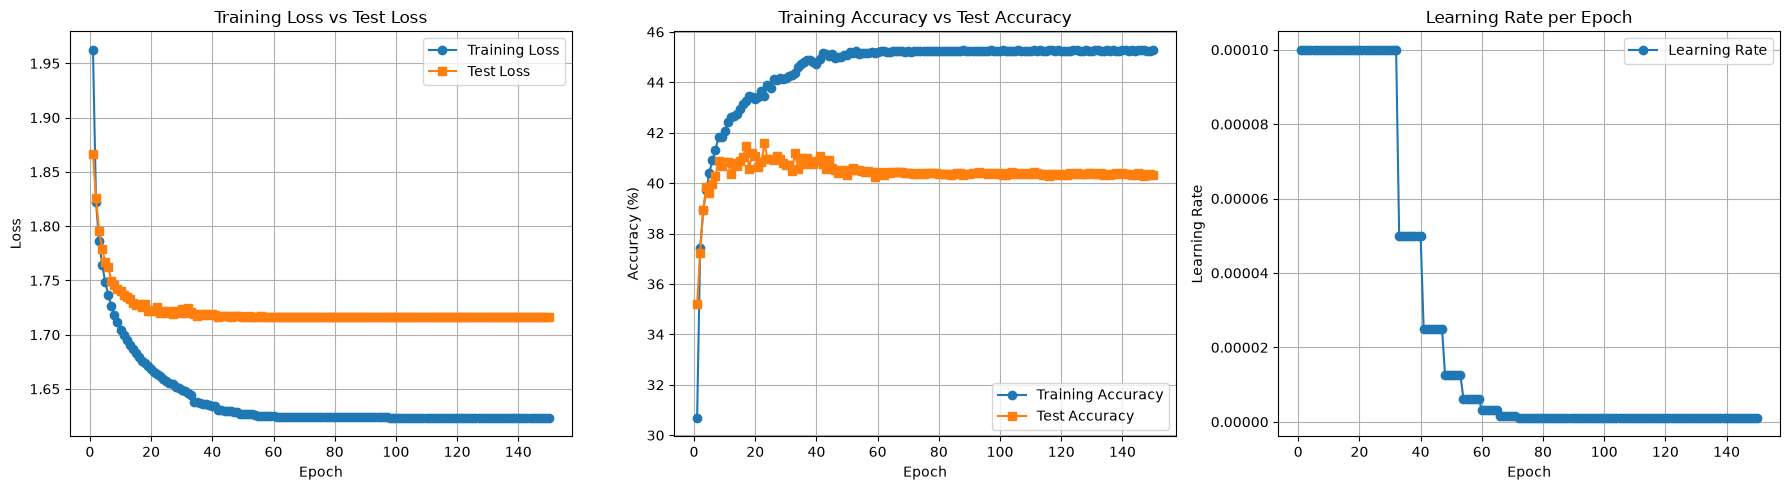

In [24]:
# Plot metrics
epochs = history["epoch"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Training Loss vs Test Loss
axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs, history["test_loss"],
    marker="s", label="Test Loss"
)
axes[0].set_title("Training Loss vs Test Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Training Accuracy vs Test Accuracy
axes[1].plot(
    epochs, history["train_acc"],
    marker="o", label="Training Accuracy"
)
axes[1].plot(
    epochs, history["test_acc"],
    marker="s", label="Test Accuracy"
)
axes[1].set_title("Training Accuracy vs Test Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

# Plot 3: Learning Rate
axes[2].plot(
    epochs, history["learning_rate"],
    marker="o", label="Learning Rate"
)
axes[2].set_title("Learning Rate per Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Learning Rate")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# Confusion Matrix

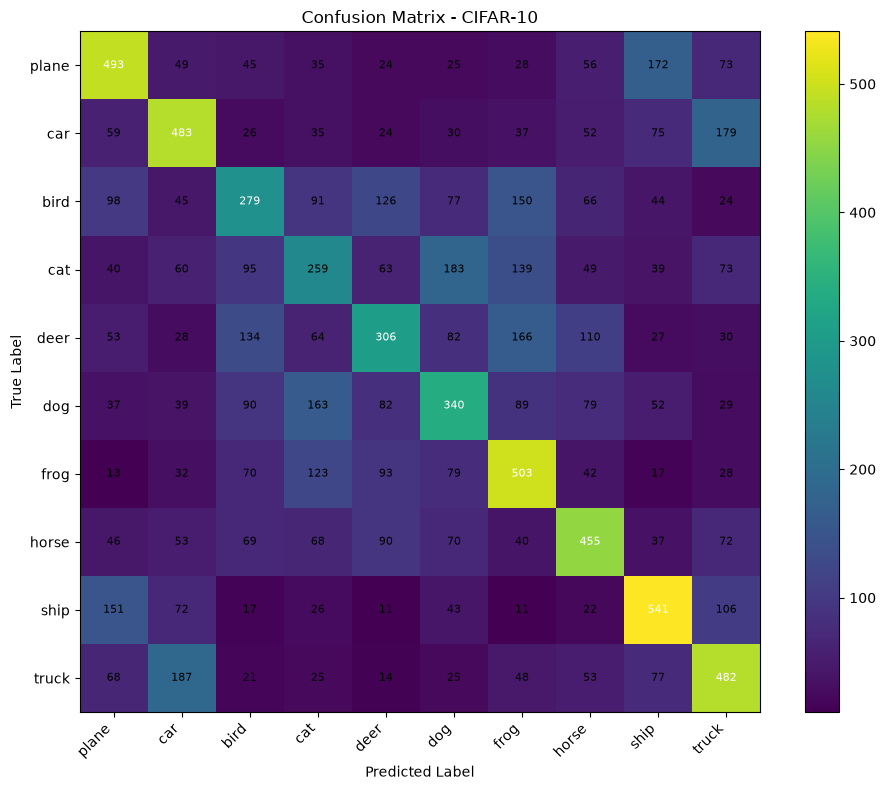

In [25]:
model.eval()

confusion_matrix = torch.zeros(
    10, 10, dtype=torch.int64
)

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        # Rows = true class; columns = predicted class
        indices = labels * 10 + predictions

        counts = torch.bincount(
            indices.cpu(), minlength=100
        ).reshape(10, 10)

        confusion_matrix += counts

cm = confusion_matrix.numpy()

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix - CIFAR-10")
fig.colorbar(im, ax=ax)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

threshold = cm.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# Display Misclassified Images

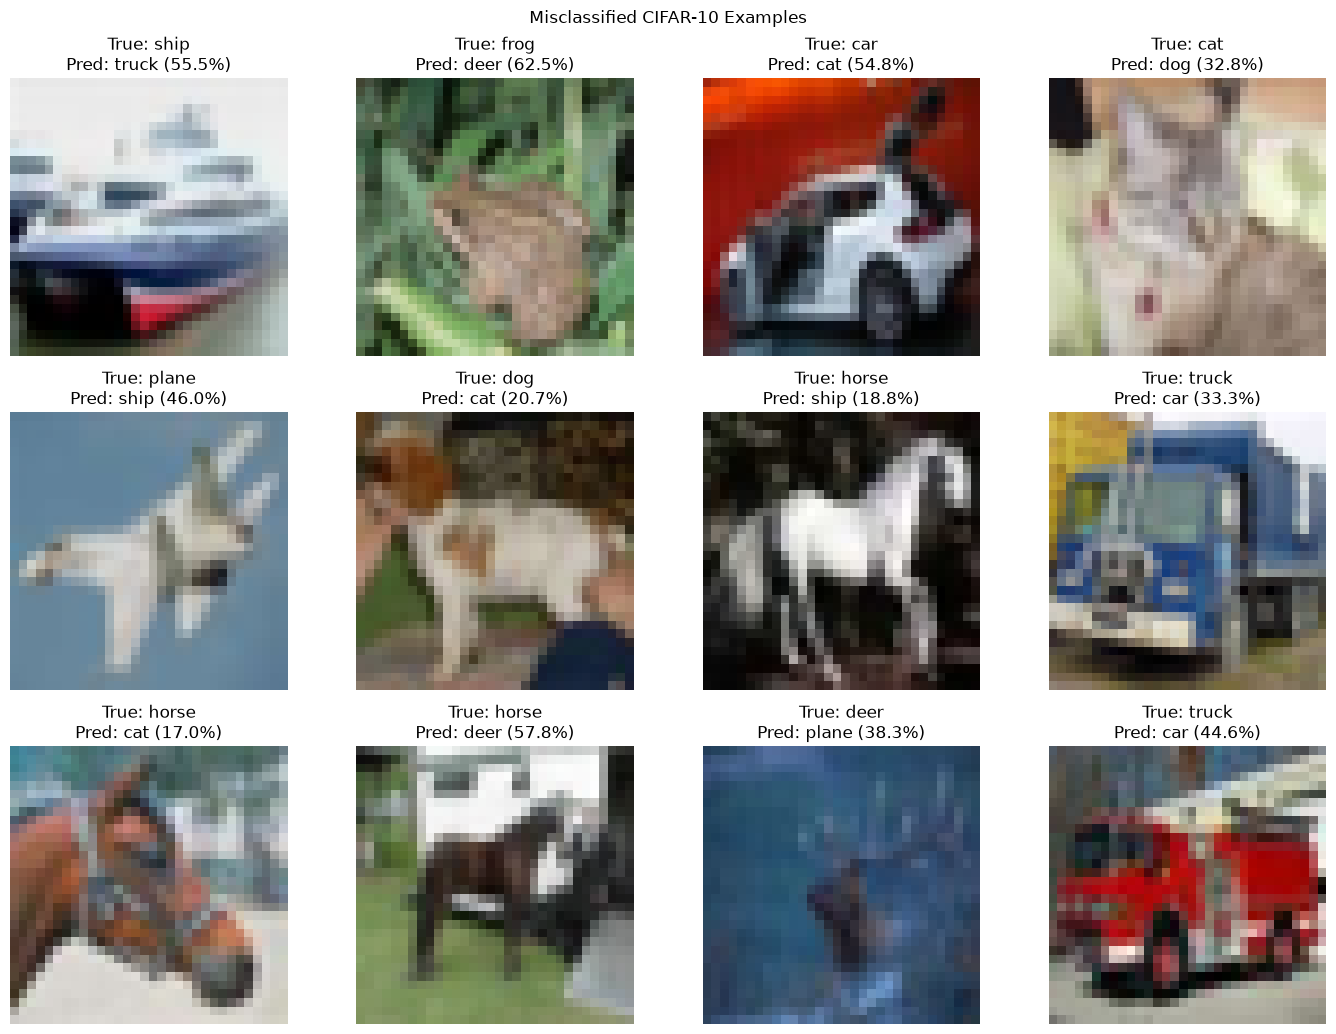


Final results
Train Loss: 1.6231
Test Loss:  1.7165
Train Acc:  45.27%
Test Acc:   40.34%
Number of model parameters: 30,730
Number of test errors: 5859


In [27]:
model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []
wrong_confidences = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)

        predictions = logits.argmax(dim=1)
        wrong_indices = (
            predictions != labels
        ).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(
                images[idx].cpu()
            )
            wrong_labels.append(
                labels[idx].item()
            )
            wrong_predictions.append(
                predictions[idx].item()
            )
            wrong_confidences.append(
                probabilities[idx, predictions[idx]].item()
            )

            # Keep the first 12 errors
            if len(wrong_images) >= 12:
                break

        if len(wrong_images) >= 12:
            break

if len(wrong_images) == 0:
    print("No misclassified examples found.")
else:
    n = len(wrong_images)
    cols = 4
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 3.5 * rows)
    )
    axes = np.asarray(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")

    for i in range(n):
        # Undo Normalize(mean=0.5, std=0.5)
        image = wrong_images[i] * 0.5 + 0.5
        image = image.permute(1, 2, 0).numpy()
        image = np.clip(image, 0, 1)

        true_name = classes[wrong_labels[i]]
        pred_name = classes[wrong_predictions[i]]
        confidence = wrong_confidences[i] * 100

        axes[i].imshow(image)
        axes[i].set_title(
            f"True: {true_name}\n"
            f"Pred: {pred_name} ({confidence:.1f}%)"
        )

    fig.suptitle("Misclassified CIFAR-10 Examples")
    plt.tight_layout()
    plt.show()

print("\nFinal results")
print(f"Train Loss: {history['train_loss'][-1]:.4f}")
print(f"Test Loss:  {history['test_loss'][-1]:.4f}")
print(f"Train Acc:  {history['train_acc'][-1]:.2f}%")
print(f"Test Acc:   {history['test_acc'][-1]:.2f}%")
print(f"Number of model parameters: {total_params:,}")
print(f"Number of test errors: {int(cm.sum() - np.trace(cm))}")
